# Sprint 1 — Conexión segura con Supabase, dataset plano y EDA inicial
**Proyecto:** Modelo Predictivo de Segmentación de Mercado y Propensión a la Matrícula · Unicervantes
(Ingeniería en Analítica de Datos e Ingeniería en Sistemas de Software e IA).

Este cuaderno cubre los tres entregables que pidió el docente para el Sprint 1:

| # | Entregable | Sección |
|---|---|---|
| 1 | Conexión funcional entre Python y Supabase con buenas prácticas de seguridad | 1 |
| 2 | Un único dataset plano con las variables principales para predecir la matrícula | 2 |
| 3 | Inicio del EDA: estadística descriptiva, distribuciones y tratamiento preliminar de nulos | 3 |

> **Sobre los datos.** Los puntajes Saber 11, el colegio, el estrato, el género y la edad de cada aspirante son
> registros **reales** y anónimos del ICFES (datos abiertos). Nombres, proceso comercial, notas del colegio y
> resultado de matrícula son **sintéticos**, generados con reglas y supuestos documentados en el repositorio.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from conexion_supabase import (TABLA, TIEMPO_LIMITE_S, crear_cliente, leer_dataset_matricula, obtener_credenciales,
                               probar_solo_lectura)

CSV_RESPALDO = RAIZ / "data" / "processed" / "dataset_matricula.csv"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#1B365D", "#E07B39", "#9AA5B1"

## 1. Conexión segura con Supabase
**Cómo se protegen las credenciales**
- La URL y la clave **no están en el código**: se leen del archivo `.env` (en el computador, excluido por
  `.gitignore`) o de los **Secretos de Colab**. El código nunca las imprime.
- Se usa la clave **publicable**, no la secreta. En la base, la seguridad a nivel de fila (RLS) le permite **solo
  leer** la tabla `dataset_matricula`; las otras 25 tablas están cerradas para la API.
- Si la clave se filtrara, solo serviría para leer este dataset anonimizado: no permite escribir ni ver datos
  personales.

**Prueba:** se leen todas las filas (la API entrega máximo 1.000 por petición, por eso se lee en páginas) y se
intenta modificar la tabla con la misma clave. La base debe rechazarlo.

In [3]:
def cargar_respaldo() -> pd.DataFrame:
    """Solo si no hay conexión: el mismo dataset exportado por el pipeline (src/s04_exportar.py)."""
    return pd.read_csv(CSV_RESPALDO)

In [4]:
USAR_CSV_DE_RESPALDO = False     # True solo si no hay acceso a Supabase (en Colab pide subir el CSV)


def motivo(error: Exception) -> str:
    """Explica el fallo sin mostrar nunca la URL ni la clave."""
    nombre = type(error).__name__
    if isinstance(error, RuntimeError):
        return str(error)
    if "Timeout" in nombre:
        return f"Supabase no respondió en {TIEMPO_LIMITE_S} s: revise la conexión a internet."
    if "Connect" in nombre:
        return "No se pudo llegar al servidor: revise SUPABASE_URL y la conexión a internet."
    codigo = getattr(error, "code", "")
    if codigo in ("PGRST301", "401") or "JWT" in str(getattr(error, "message", "")) or "API key" in str(error):
        return "La clave fue rechazada: revise que SUPABASE_KEY sea la clave publicable del proyecto."
    return f"{nombre}: revise la URL, la clave y la red."


if USAR_CSV_DE_RESPALDO:
    df, ORIGEN = cargar_respaldo(), "archivo CSV de respaldo (sin conexión)"
else:
    try:
        print("Paso 1/3: leyendo las credenciales (en Colab, acepte el aviso de acceso a los secretos si aparece)…", flush=True)
        url, clave = obtener_credenciales()                      # de .env o de los Secretos; no se muestran
        print("Paso 2/3: conectando con la API de Supabase…", flush=True)
        cliente = crear_cliente(url, clave)
        df = leer_dataset_matricula(cliente)
        del url, clave
        print("Paso 3/3: probando que la clave NO pueda escribir…", flush=True)
        rechazada = probar_solo_lectura(cliente)
    except Exception as error:
        raise SystemExit(f"No fue posible conectar con Supabase. {motivo(error)}\n"
                         "Corrija el problema y vuelva a ejecutar esta celda "
                         "(o use USAR_CSV_DE_RESPALDO = True).") from None
    ORIGEN = "Supabase (API de solo lectura)"
    print(f"\nConexión exitosa: {len(df):,} filas y {df.shape[1]} columnas leídas de la tabla '{TABLA}'.")
    print("Prueba de escritura con la misma clave:",
          "RECHAZADA por la base (permiso denegado). La clave solo puede leer." if rechazada
          else "NO fue rechazada: revisar las políticas RLS.")
print("Origen de los datos:", ORIGEN)

Paso 1/3: leyendo las credenciales (en Colab, acepte el aviso de acceso a los secretos si aparece)…


Paso 2/3: conectando con la API de Supabase…


Paso 3/3: probando que la clave NO pueda escribir…



Conexión exitosa: 2,991 filas y 48 columnas leídas de la tabla 'dataset_matricula'.
Prueba de escritura con la misma clave: RECHAZADA por la base (permiso denegado). La clave solo puede leer.
Origen de los datos: Supabase (API de solo lectura)


## 2. Dataset plano para el modelo de matrícula
La base de datos tiene dos capas:
- **Capa transaccional (OLTP):** 25 tablas normalizadas que registran el proceso de admisión. Es la fuente.
- **Capa analítica (OLAP):** la tabla **`dataset_matricula`**, ya consolidada en Supabase. Tiene **una fila por
  inscrito** y una columna por variable. La **distancia al campus** y el **promedio del colegio** vienen calculados.
  Python no necesita unir tablas.

Roles de las columnas:
- **Control** (no son predictores): `inscripcion_id`, `periodo`, `conjunto`.
- **Objetivo:** `matriculado` (1 = pagó la matrícula del primer semestre).
- **Predictores:** el resto. Se excluyeron los datos personales y las variables con **fuga de datos** (por ejemplo,
  documentos entregados o forma de financiación, que solo se conocen al matricularse).

`conjunto` separa el histórico con resultado (`ENTRENAMIENTO`, 2024-1 a 2026-2) de la campaña abierta
(`CAMPANA_2027_1`), cuyo resultado aún no existe y es lo que el modelo predecirá.

In [5]:
CONTROL = ["inscripcion_id", "periodo", "conjunto"]
OBJETIVO = "matriculado"
NUMERICAS = ["edad_al_inscribirse", "estrato", "distancia_campus_km", "distancia_vial_km", "dias_registro_a_inscripcion",
             "contactos_antes_de_inscribirse", "colegio_promedio_saber11", "anios_desde_saber11",
             "punt_lectura_critica", "punt_matematicas", "punt_sociales", "punt_ciencias", "punt_ingles", "punt_global",
             "promedio_acumulado_colegio", "promedio_matematicas_colegio", "puntaje_vocacional",
             "pct_descuento_inicial", "valor_semestre_bruto", "valor_neto_primer_semestre"]
BINARIAS = ["captado_en_evento", "colegio_en_convenio", "entrevista_realizada", "cumple_req_saber11",
            "cumple_req_mi_vocacion", "elegible_foes", "apoyo_foes"]
CATEGORICAS = ["programa", "genero", "nacionalidad", "estado_civil", "regimen_salud", "tipo_ubicacion", "ciudad",
               "departamento", "canal", "asesor_id", "colegio_naturaleza", "colegio_caracter", "colegio_bilingue",
               "tipo_colegio", "colegio_nivel", "desempeno_bachillerato", "beca"]
PREDICTORES = NUMERICAS + BINARIAS + CATEGORICAS
assert sorted(CONTROL + [OBJETIVO] + PREDICTORES) == sorted(df.columns), "Columnas inesperadas en el dataset"

# Tipos: la API devuelve JSON; los enteros con vacíos se guardan como Int64 (no como 1.0 / 0.0)
for c in [OBJETIVO, "puntaje_vocacional"]:
    df[c] = pd.to_numeric(df[c]).astype("Int64")
for c in NUMERICAS + BINARIAS:
    df[c] = pd.to_numeric(df[c])
df["asesor_id"] = df["asesor_id"].astype(str)
df = df.sort_values("inscripcion_id").reset_index(drop=True)

print(f"Forma: {df.shape[0]:,} filas × {df.shape[1]} columnas · {len(NUMERICAS)} numéricas, "
      f"{len(BINARIAS)} binarias, {len(CATEGORICAS)} categóricas, 1 objetivo y {len(CONTROL)} de control")
df.head()

Forma: 2,991 filas × 48 columnas · 20 numéricas, 7 binarias, 17 categóricas, 1 objetivo y 3 de control


,inscripcion_id,periodo,programa,conjunto,matriculado,genero,edad_al_inscribirse,estrato,nacionalidad,estado_civil,regimen_salud,tipo_ubicacion,ciudad,departamento,distancia_campus_km,distancia_vial_km,canal,captado_en_evento,asesor_id,dias_registro_a_inscripcion,contactos_antes_de_inscribirse,colegio_naturaleza,colegio_caracter,colegio_bilingue,tipo_colegio,colegio_nivel,colegio_promedio_saber11,colegio_en_convenio,anios_desde_saber11,punt_lectura_critica,punt_matematicas,punt_sociales,punt_ciencias,punt_ingles,punt_global,promedio_acumulado_colegio,promedio_matematicas_colegio,desempeno_bachillerato,entrevista_realizada,puntaje_vocacional,cumple_req_saber11,cumple_req_mi_vocacion,beca,pct_descuento_inicial,valor_semestre_bruto,valor_neto_primer_semestre,elegible_foes,apoyo_foes
0,1,2026-1,AD,ENTRENAMIENTO,0,M,16,1,COLOMBIA,SOLTERO,CONTRIBUTIVO,MUNICIPIO,Cota,CUNDINAMARCA,4.410,6.050,COLEGIO_CONVENIO,0,2,51,4,PRIVADO,ACADÉMICO,NaN,PRIVADO,MEDIO,272.100,1,0,69,73,59,59,65,325,4.360,4.400,ALTO,1,4,1,1,SABER_11,0.300,4914000,3439800,0,0
1,2,2025-1,AD,ENTRENAMIENTO,0,F,16,4,COLOMBIA,SOLTERO,CONTRIBUTIVO,LOCALIDAD,Bogotá D.C.,BOGOTÁ D.C.,8.190,10.810,LLAMADA_WHATSAPP,0,5,31,3,PRIVADO,ACADÉMICO,NO,PRIVADO,ALTO,305.900,0,0,66,59,52,56,77,298,3.830,3.650,BASICO,1,2,0,0,NINGUNA,0.000,4658000,4658000,0,0
2,3,2025-2,AD,ENTRENAMIENTO,0,M,21,3,COLOMBIA,SOLTERO,CONTRIBUTIVO,LOCALIDAD,Bogotá D.C.,BOGOTÁ D.C.,9.930,13.100,LLAMADA_WHATSAPP,0,1,15,3,PRIVADO,NaN,NaN,PRIVADO,BAJO,222.300,0,4,54,43,36,50,47,229,4.050,3.850,ALTO,1,3,0,1,NINGUNA,0.000,4658000,4658000,0,0
3,4,2026-2,AD,ENTRENAMIENTO,0,M,18,2,COLOMBIA,SOLTERO,CONTRIBUTIVO,LOCALIDAD,Bogotá D.C.,BOGOTÁ D.C.,5.070,6.400,CAMPUS_DAY,1,3,10,1,OFICIAL,ACADÉMICO,NO,OFICIAL,BAJO,254.700,0,0,56,53,47,50,47,256,3.570,3.450,BASICO,0,<NA>,0,0,NINGUNA,0.000,4914000,4914000,0,0
4,5,2026-2,AD,ENTRENAMIENTO,1,M,18,3,COLOMBIA,SOLTERO,CONTRIBUTIVO,LOCALIDAD,Bogotá D.C.,BOGOTÁ D.C.,6.670,8.790,INMERSION,0,4,6,2,PRIVADO,ACADÉMICO,NO,PRIVADO,ALTO,307.900,0,1,71,72,64,65,71,341,3.320,3.350,BASICO,1,4,1,1,SABER_11,0.300,4914000,3439800,0,0


In [6]:
rol = {**{c: "control" for c in CONTROL}, OBJETIVO: "objetivo", **{c: "numérica" for c in NUMERICAS},
       **{c: "binaria 0/1" for c in BINARIAS}, **{c: "categórica" for c in CATEGORICAS}}
resumen = pd.DataFrame({"rol": pd.Series(rol), "tipo_python": df.dtypes.astype(str),
                        "valores_distintos": df.nunique(), "nulos": df.isna().sum(),
                        "pct_nulos": (df.isna().mean() * 100).round(1)}).loc[df.columns]
display(resumen)

chequeos = {
    "inscripcion_id sin duplicados": df["inscripcion_id"].is_unique,
    "distancia al campus calculada en todas las filas": df["distancia_campus_km"].notna().all(),
    "promedio del colegio calculado en todas las filas": df["promedio_acumulado_colegio"].notna().all(),
    "objetivo vacío solo en la campaña 2027-1": (df[OBJETIVO].isna() == (df["conjunto"] == "CAMPANA_2027_1")).all(),
}
for nombre, ok in chequeos.items():
    print(("✔ " if ok else "✘ ") + nombre)
print("\nFilas por conjunto:", df["conjunto"].value_counts().to_dict())

,rol,tipo_python,valores_distintos,nulos,pct_nulos
inscripcion_id,control,int64,2991,0,0.000
periodo,control,str,7,0,0.000
programa,categórica,str,2,0,0.000
conjunto,control,str,2,0,0.000
matriculado,objetivo,Int64,2,416,13.900
genero,categórica,str,2,0,0.000
edad_al_inscribirse,numérica,int64,16,0,0.000
estrato,numérica,int64,6,0,0.000
nacionalidad,categórica,str,3,0,0.000
estado_civil,categórica,str,3,0,0.000


✔ inscripcion_id sin duplicados
✔ distancia al campus calculada en todas las filas
✔ promedio del colegio calculado en todas las filas
✔ objetivo vacío solo en la campaña 2027-1

Filas por conjunto: {'ENTRENAMIENTO': 2575, 'CAMPANA_2027_1': 416}


## 3. Análisis exploratorio inicial (EDA)
El EDA se hace sobre el conjunto de **ENTRENAMIENTO** (periodos con resultado). La campaña 2027-1 se describe aparte
y no se mira su objetivo, para no tomar decisiones con datos que el modelo deberá predecir.

### 3.1 Estadística descriptiva

In [7]:
ent = df[df["conjunto"] == "ENTRENAMIENTO"].copy()
camp = df[df["conjunto"] == "CAMPANA_2027_1"].copy()
print(f"Entrenamiento: {len(ent):,} inscritos · Campaña 2027-1: {len(camp):,} inscritos")

num = ent[NUMERICAS].astype(float)
desc = num.describe().T
desc["asimetria"] = num.skew()
desc["curtosis"] = num.kurt()
desc["coef_variacion"] = desc["std"] / desc["mean"]
desc.round(3)

Entrenamiento: 2,575 inscritos · Campaña 2027-1: 416 inscritos


,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis,coef_variacion
edad_al_inscribirse,"2,575.000",18.236,1.892,15.000,17.000,18.000,19.000,30.000,1.784,4.664,0.104
estrato,"2,575.000",2.763,0.763,1.000,2.000,3.000,3.000,6.000,0.481,0.440,0.276
distancia_campus_km,"2,575.000",12.294,7.326,3.130,7.030,8.940,16.280,37.390,0.906,-0.346,0.596
distancia_vial_km,"2,575.000",15.622,9.057,4.280,8.940,11.760,21.250,51.940,0.899,-0.375,0.580
dias_registro_a_inscripcion,"2,575.000",31.296,32.998,0.000,12.000,21.000,37.000,209.000,2.549,7.348,1.054
contactos_antes_de_inscribirse,"2,575.000",2.261,1.347,0.000,1.000,2.000,3.000,8.000,0.570,0.299,0.596
colegio_promedio_saber11,"2,575.000",272.849,27.415,191.300,254.300,266.700,290.700,373.300,0.679,0.253,0.100
anios_desde_saber11,"2,575.000",0.867,1.510,0.000,0.000,0.000,1.000,8.000,2.398,6.218,1.742
punt_lectura_critica,"2,575.000",56.820,8.931,27.000,51.000,57.000,63.000,81.000,-0.252,-0.225,0.157
punt_matematicas,"2,575.000",55.981,10.249,21.000,49.000,57.000,63.000,100.000,-0.186,0.330,0.183


In [8]:
filas = []
for c in CATEGORICAS + BINARIAS:
    frec = ent[c].value_counts(normalize=True, dropna=False)
    filas.append({"variable": c, "categorias": ent[c].nunique(dropna=True),
                  "mas_frecuente": frec.index[0], "pct_mas_frecuente": round(100 * frec.iloc[0], 1),
                  "segunda": frec.index[1] if len(frec) > 1 else "-",
                  "pct_segunda": round(100 * frec.iloc[1], 1) if len(frec) > 1 else 0.0})
pd.DataFrame(filas).set_index("variable")

,categorias,mas_frecuente,pct_mas_frecuente,segunda,pct_segunda
variable,,,,,
programa,2,AD,82.800,SSIA,17.200
genero,2,M,66.400,F,33.600
nacionalidad,3,COLOMBIA,99.200,VENEZUELA,0.700
estado_civil,3,SOLTERO,97.700,UNION_LIBRE,1.900
regimen_salud,3,CONTRIBUTIVO,78.600,SUBSIDIADO,19.000
tipo_ubicacion,2,LOCALIDAD,91.500,MUNICIPIO,8.500
ciudad,12,Bogotá D.C.,91.500,Chía,4.200
departamento,2,BOGOTÁ D.C.,91.500,CUNDINAMARCA,8.500
canal,8,REFERIDO,20.500,REDES_SOCIALES,15.800


In [9]:
tasa = ent[OBJETIVO].astype(float).mean()
print(f"Tasa de matrícula en entrenamiento: {tasa:.1%} ({int(ent[OBJETIVO].sum()):,} de {len(ent):,} inscritos)")
balance = ent.groupby(["periodo", "programa"])[OBJETIVO].agg(inscritos="size", matriculados="sum", tasa="mean")
balance["tasa"] = balance["tasa"].astype(float).round(3)
balance

Tasa de matrícula en entrenamiento: 45.6% (1,173 de 2,575 inscritos)


inscritos  matriculados  tasa
periodo programa                               
2024-1  AD              358           167 0.466
2024-2  AD              207            90 0.435
2025-1  AD              462           226 0.489
2025-2  AD              283           138 0.488
2026-1  AD              504           214 0.425
2026-2  AD              318           133 0.418
        SSIA            443           205 0.463

**Lectura de la estadística descriptiva**
- El objetivo está **balanceado**: cerca de la mitad de los inscritos se matricula y la tasa es estable entre
  periodos. No hace falta sobremuestreo, pero conviene validar por periodo.
- Los puntajes Saber 11 y el promedio del colegio tienen asimetría cercana a 0: son casi simétricos.
- La **distancia al campus** (asimetría ≈ 0,9), los **días entre registro e inscripción** (≈ 2,5), la **edad** (≈ 1,8) y
  los **años desde el Saber 11** (≈ 2,4) tienen cola larga a la derecha. Son candidatas a transformación logarítmica
  o a agruparse en rangos en el Sprint 2.
- Variables como `valor_semestre_bruto` casi no varían dentro de un programa y un año: aportan poco por sí solas,
  pero el **valor neto** (después de la beca) sí varía.

### 3.2 Distribuciones

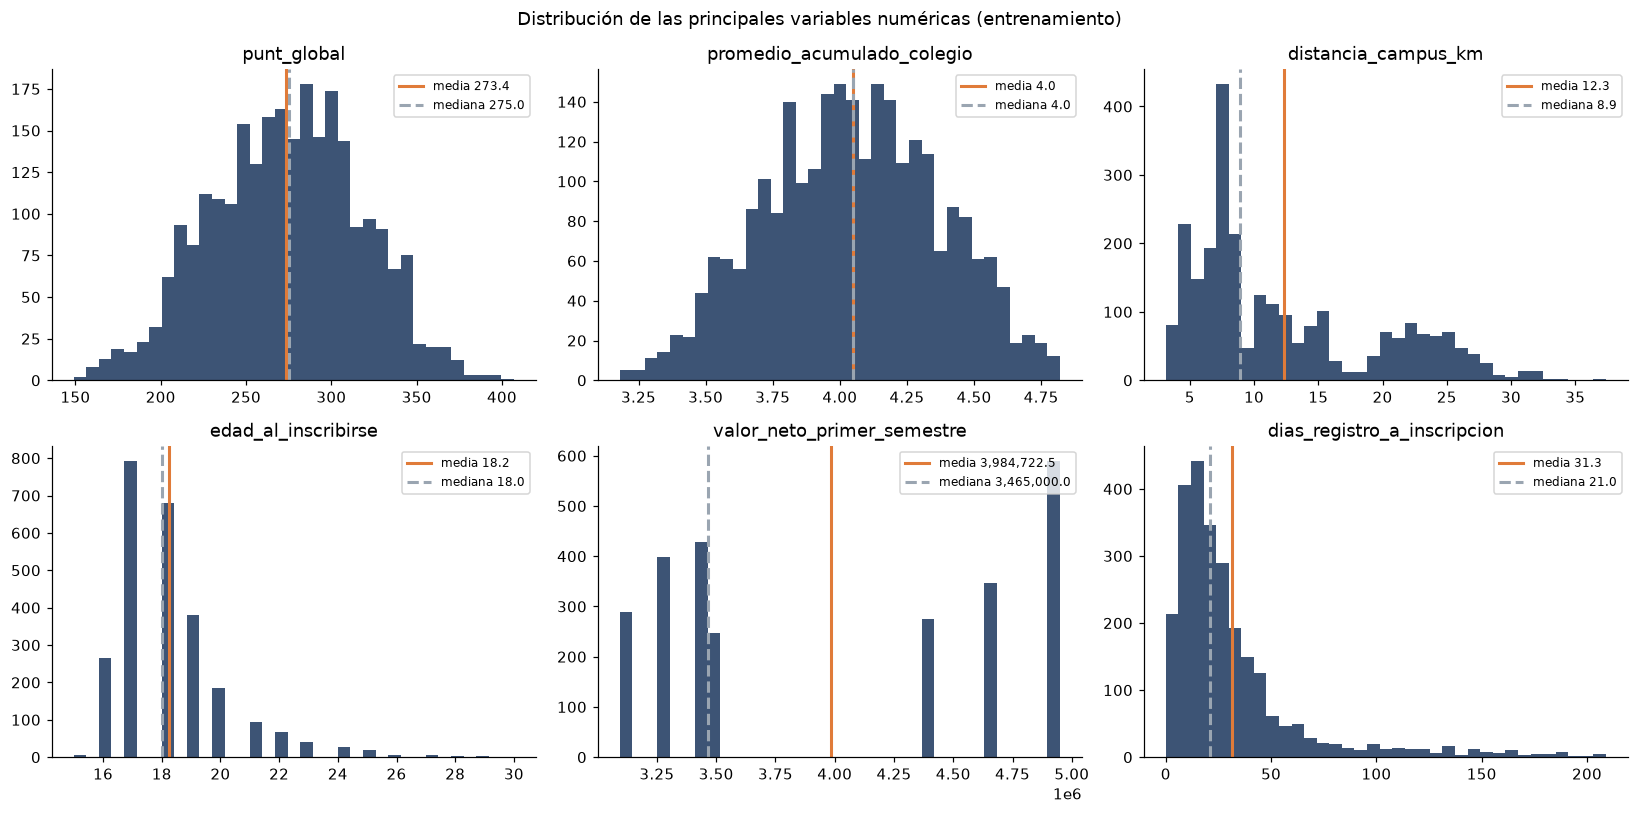

In [10]:
variables = ["punt_global", "promedio_acumulado_colegio", "distancia_campus_km", "edad_al_inscribirse",
             "valor_neto_primer_semestre", "dias_registro_a_inscripcion"]
fig, ejes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(ejes.flat, variables):
    x = ent[c].astype(float)
    ax.hist(x, bins=35, color=AZUL, alpha=0.85)
    ax.axvline(x.mean(), color=NARANJA, lw=2, label=f"media {x.mean():,.1f}")
    ax.axvline(x.median(), color=GRIS, lw=2, ls="--", label=f"mediana {x.median():,.1f}")
    ax.set_title(c)
    ax.legend(fontsize=8)
fig.suptitle("Distribución de las principales variables numéricas (entrenamiento)")
plt.tight_layout()
plt.show()

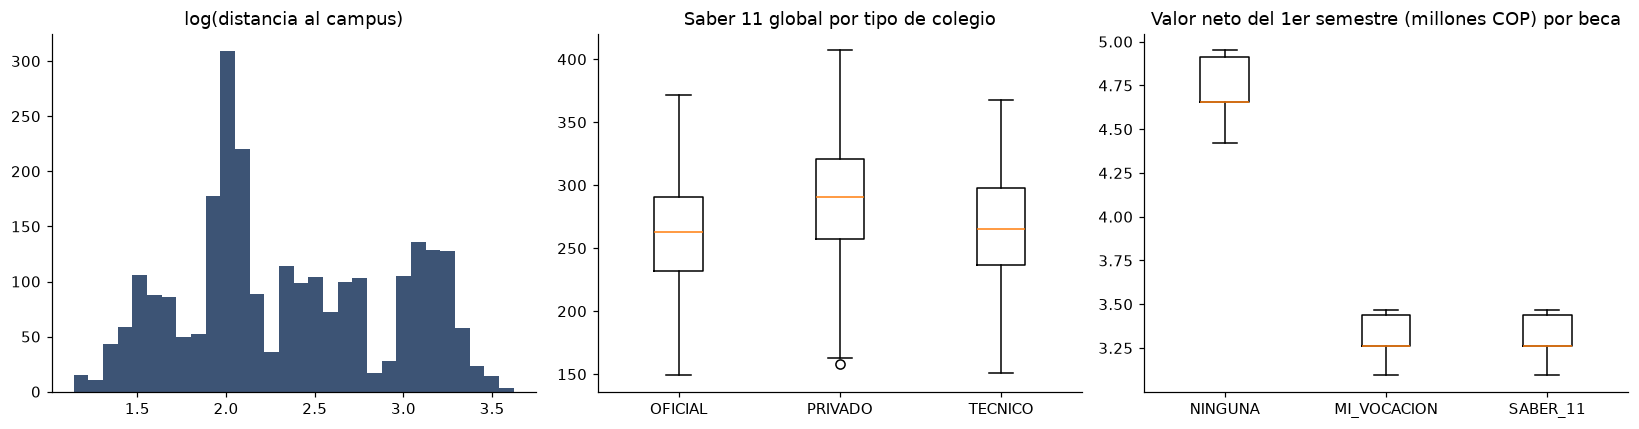

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(np.log(ent["distancia_campus_km"].astype(float)), bins=30, color=AZUL, alpha=0.85)
ejes[0].set_title("log(distancia al campus)")
ejes[1].boxplot([ent.loc[ent["tipo_colegio"] == t, "punt_global"] for t in ["OFICIAL", "PRIVADO", "TECNICO"]])
ejes[1].set_xticks([1, 2, 3], ["OFICIAL", "PRIVADO", "TECNICO"])
ejes[1].set_title("Saber 11 global por tipo de colegio")
ejes[2].boxplot([ent.loc[ent["beca"] == b, "valor_neto_primer_semestre"] / 1e6 for b in ["NINGUNA", "MI_VOCACION", "SABER_11"]])
ejes[2].set_xticks([1, 2, 3], ["NINGUNA", "MI_VOCACION", "SABER_11"])
ejes[2].set_title("Valor neto del 1er semestre (millones COP) por beca")
plt.tight_layout()
plt.show()

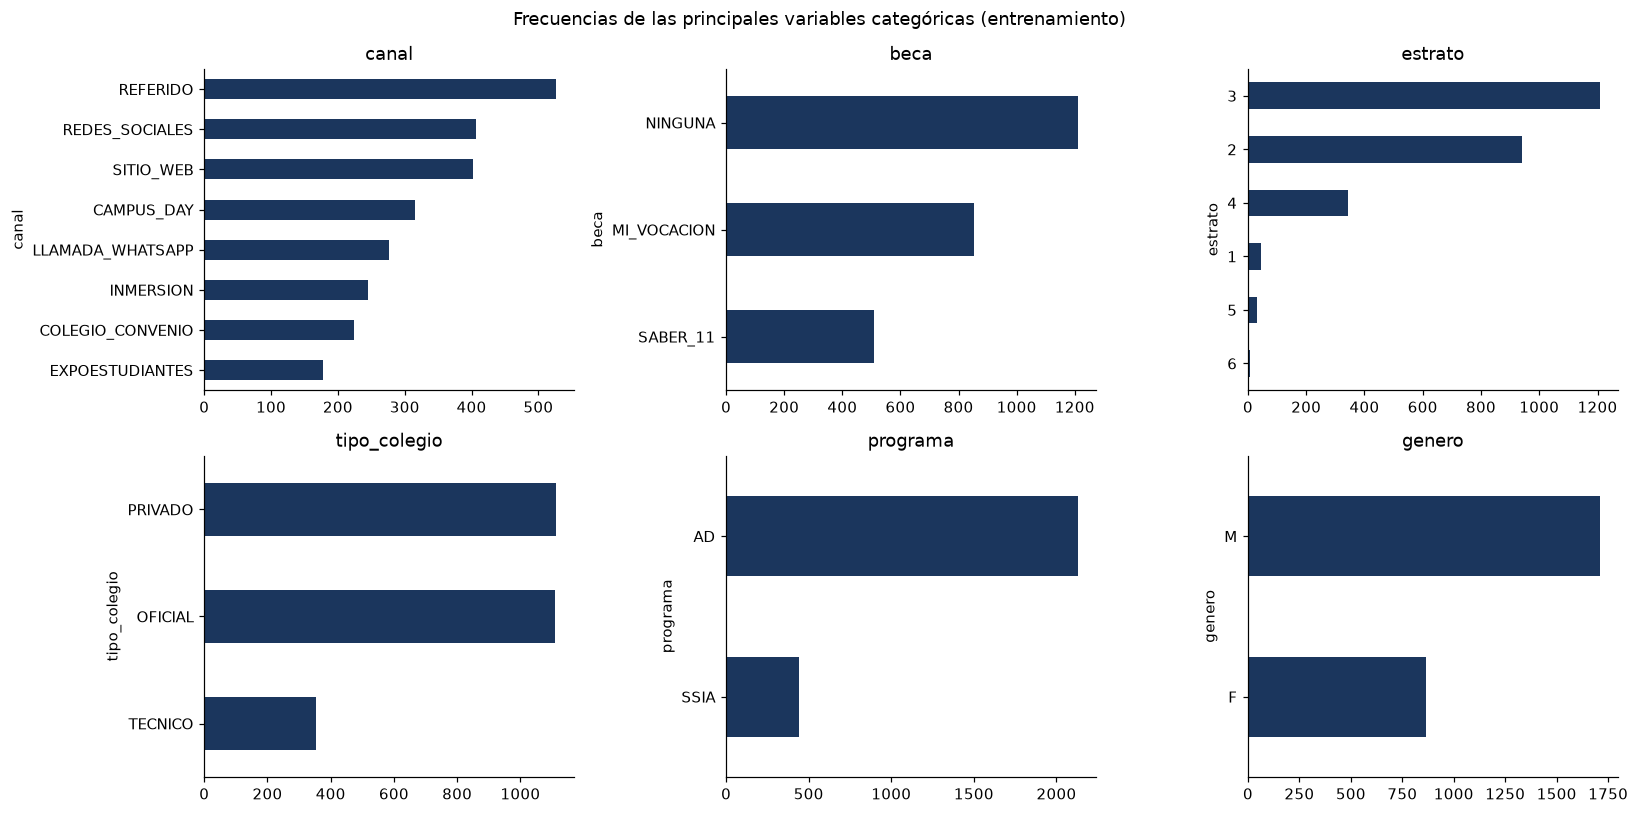

In [12]:
fig, ejes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(ejes.flat, ["canal", "beca", "estrato", "tipo_colegio", "programa", "genero"]):
    ent[c].value_counts().sort_values().plot(kind="barh", ax=ax, color=AZUL)
    ax.set_title(c)
fig.suptitle("Frecuencias de las principales variables categóricas (entrenamiento)")
plt.tight_layout()
plt.show()

In [13]:
def atipicos_iqr(s: pd.Series) -> dict:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    bajo, alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {"limite_inferior": bajo, "limite_superior": alto, "por_debajo": int((s < bajo).sum()),
            "por_encima": int((s > alto).sum()), "pct_atipicos": round(100 * ((s < bajo) | (s > alto)).mean(), 1)}

atip = pd.DataFrame({c: atipicos_iqr(ent[c].astype(float).dropna()) for c in NUMERICAS}).T
atip[atip["pct_atipicos"] > 0].sort_values("pct_atipicos", ascending=False)

,limite_inferior,limite_superior,por_debajo,por_encima,pct_atipicos
anios_desde_saber11,-1.500,2.500,0.000,301.000,11.700
dias_registro_a_inscripcion,-25.500,74.500,0.000,212.000,8.200
puntaje_vocacional,1.500,5.500,95.000,0.000,4.400
edad_al_inscribirse,14.000,22.000,0.000,103.000,4.000
estrato,0.500,4.500,0.000,37.000,1.400
distancia_campus_km,-6.845,30.155,0.000,37.000,1.400
colegio_promedio_saber11,199.700,345.300,1.000,25.000,1.000
punt_matematicas,28.000,84.000,12.000,4.000,0.600
punt_ingles,24.000,88.000,1.000,13.000,0.500
punt_lectura_critica,33.000,81.000,11.000,0.000,0.400


**Lectura de las distribuciones**
- El 42% de los inscritos vive a 8 km o menos del campus en línea recta (sobre todo en Suba, Usaquén, Chía y Cota). Por
  vías, el 36% está a 10 km o menos y el 28% a más de 20 km: una cola larga hacia el centro y el sur de Bogotá (hasta
  52 km por vía) y el norte de la Sabana. En escala logarítmica la distribución es más simétrica.
- **Distancia por dirección:** cada inscrito tiene una dirección real (placa de Catastro Bogotá o dirección del DANE en
  Sabana Centro, asignada al azar a una persona ficticia). La distancia se calcula desde esa coordenada, en línea recta
  y por vías (estimada: tramo norte-sur + oriente-occidente, S-44); por eso hay casi un valor distinto por inscrito.
- Los colegios privados tienen puntajes Saber 11 más altos que los oficiales. Es el mismo patrón de los datos reales
  del ICFES.
- El valor neto se separa en grupos por beca: la beca baja el valor del primer semestre en 30%.
- Los **atípicos** (regla de 1,5 × IQR) son valores posibles: personas adultas, residencias lejanas, puntajes muy altos.
  **No se eliminan**: se marcan. En el Sprint 2 la distancia pasó a escala logarítmica (`log_distancia`) y se
  agrupó en zonas; los demás se conservan tal cual.

### 3.3 Valores nulos
No todos los vacíos significan lo mismo. Se clasifican antes de tratarlos:

,nulos,pct,nulos_entrenamiento,nulos_campana,tipo,por_que,tratamiento
matriculado,416,13.900,0,416,Censura,Campaña 2027-1: el resultado aún no ocurre,No se imputa: es el conjunto a predecir
colegio_caracter,122,4.100,102,20,Faltante real (ICFES),El ICFES no reporta el carácter de ese colegio,Categoría NO_REPORTA
colegio_bilingue,534,17.900,456,78,Faltante real (ICFES),El ICFES no reporta si el colegio es bilingüe,Categoría NO_REPORTA
puntaje_vocacional,467,15.600,404,63,Estructural,No hubo entrevista con psicología,0 = sin valoración (entrevista_realizada ya lo...


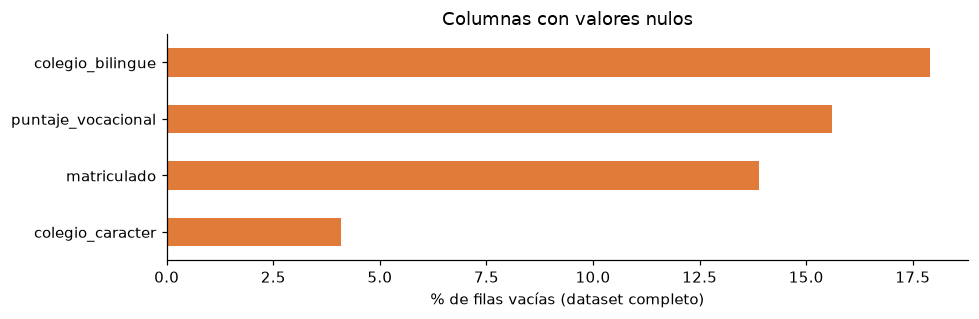

In [14]:
TIPO_NULO = {
    "matriculado": ("Censura", "Campaña 2027-1: el resultado aún no ocurre", "No se imputa: es el conjunto a predecir"),
    "puntaje_vocacional": ("Estructural", "No hubo entrevista con psicología", "0 = sin valoración (entrevista_realizada ya lo indica)"),
    "colegio_caracter": ("Faltante real (ICFES)", "El ICFES no reporta el carácter de ese colegio", "Categoría NO_REPORTA"),
    "colegio_bilingue": ("Faltante real (ICFES)", "El ICFES no reporta si el colegio es bilingüe", "Categoría NO_REPORTA"),
}
nulos = df.isna().sum()
nulos = nulos[nulos > 0]
tabla_nulos = pd.DataFrame({"nulos": nulos, "pct": (100 * nulos / len(df)).round(1),
                            "nulos_entrenamiento": ent[nulos.index].isna().sum(),
                            "nulos_campana": camp[nulos.index].isna().sum()})
tabla_nulos[["tipo", "por_que", "tratamiento"]] = [TIPO_NULO.get(c, ("Sin clasificar", "-", "-")) for c in tabla_nulos.index]
display(tabla_nulos)

fig, ax = plt.subplots(figsize=(9, 3))
tabla_nulos["pct"].sort_values().plot(kind="barh", ax=ax, color=NARANJA)
ax.set_xlabel("% de filas vacías (dataset completo)")
ax.set_title("Columnas con valores nulos")
plt.tight_layout()
plt.show()

In [15]:
# ¿Los vacíos son como se dijo? Se comprueba en vez de suponerlo
print("puntaje_vocacional vacío ⇔ sin entrevista:",
      (df["puntaje_vocacional"].isna() == (df["entrevista_realizada"] == 0)).all())
print("matriculado vacío ⇔ campaña 2027-1:", (df[OBJETIVO].isna() == (df["conjunto"] == "CAMPANA_2027_1")).all())
print("\nColegios sin carácter o sin dato de bilingüismo, por naturaleza (% de inscritos):")
print(df.assign(sin_caracter=df["colegio_caracter"].isna(), sin_bilingue=df["colegio_bilingue"].isna())
        .groupby("colegio_naturaleza")[["sin_caracter", "sin_bilingue"]].mean().mul(100).round(1))

puntaje_vocacional vacío ⇔ sin entrevista: True
matriculado vacío ⇔ campaña 2027-1: True

Colegios sin carácter o sin dato de bilingüismo, por naturaleza (% de inscritos):
                    sin_caracter  sin_bilingue
colegio_naturaleza                            
OFICIAL                    2.200        15.100
PRIVADO                    6.200        21.000


### 3.4 Tratamiento preliminar de nulos
Decisiones (todas reversibles; el dataset de Supabase no se modifica):
1. **Objetivo vacío:** no se imputa. La campaña 2027-1 se separa como conjunto de predicción.
2. **`puntaje_vocacional` vacío:** se reemplaza por **0 = sin valoración**. No se usa la media porque el vacío tiene
   significado (no hubo entrevista) y `entrevista_realizada` ya lo marca.
3. **`colegio_caracter` y `colegio_bilingue` vacíos:** nueva categoría **`NO_REPORTA`**. Imputar la moda inventaría
   un dato que el ICFES no tiene.

En el Sprint 3 este tratamiento quedó dentro del *pipeline* de scikit-learn (`modelado.preparar_X` y
`modelado.construir_pipeline`). Así se aplica igual en entrenamiento, validación y campaña, sin fuga de información.

In [16]:
def tratamiento_preliminar(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    d["puntaje_vocacional"] = d["puntaje_vocacional"].fillna(0).astype(int)
    for c in ["colegio_caracter", "colegio_bilingue"]:
        d[c] = d[c].fillna("NO_REPORTA")
    return d

ent_t, camp_t = tratamiento_preliminar(ent), tratamiento_preliminar(camp)
antes = ent[PREDICTORES].isna().sum()
despues = ent_t[PREDICTORES].isna().sum()
print(pd.DataFrame({"antes": antes[antes > 0], "despues": despues[antes > 0]}))
assert despues.sum() == 0 and camp_t[PREDICTORES].isna().sum().sum() == 0
print(f"\nPredictores sin nulos: entrenamiento {ent_t.shape} y campaña {camp_t.shape}. "
      "El objetivo de la campaña sigue vacío a propósito.")

                    antes  despues
puntaje_vocacional    404        0
colegio_caracter      102        0
colegio_bilingue      456        0

Predictores sin nulos: entrenamiento (2575, 48) y campaña (416, 48). El objetivo de la campaña sigue vacío a propósito.


### 3.5 Primera mirada a la relación con la matrícula
Es un primer acercamiento (correlaciones y tasas por grupo), no el modelo. Sirve para priorizar variables en el
Sprint 2.

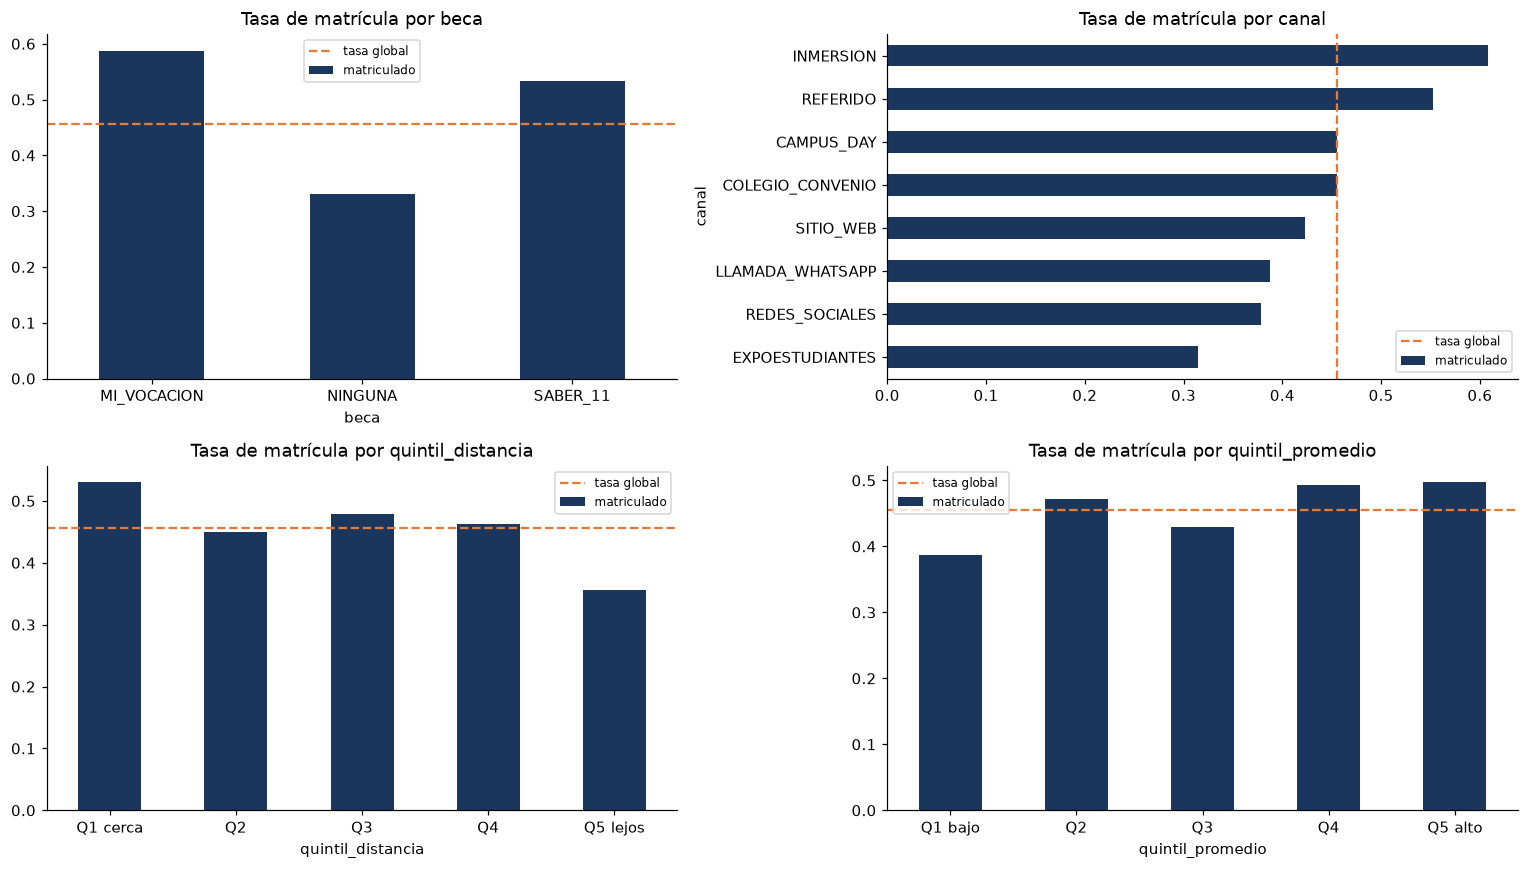

In [17]:
t = ent_t.assign(quintil_distancia=pd.qcut(ent_t["distancia_vial_km"].rank(method="first"), 5,
                                           labels=["Q1 cerca", "Q2", "Q3", "Q4", "Q5 lejos"]),
                quintil_promedio=pd.qcut(ent_t["promedio_acumulado_colegio"].rank(method="first"), 5,
                                         labels=["Q1 bajo", "Q2", "Q3", "Q4", "Q5 alto"]))
t[OBJETIVO] = t[OBJETIVO].astype(float)
fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
for ax, c in zip(ejes.flat, ["beca", "canal", "quintil_distancia", "quintil_promedio"]):
    tasas = t.groupby(c, observed=True)[OBJETIVO].mean()
    if c == "canal":
        tasas = tasas.sort_values()
    tasas.plot(kind="barh" if c == "canal" else "bar", ax=ax, color=AZUL)
    (ax.axvline if c == "canal" else ax.axhline)(t[OBJETIVO].mean(), color=NARANJA, ls="--", label="tasa global")
    ax.set_title(f"Tasa de matrícula por {c}")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

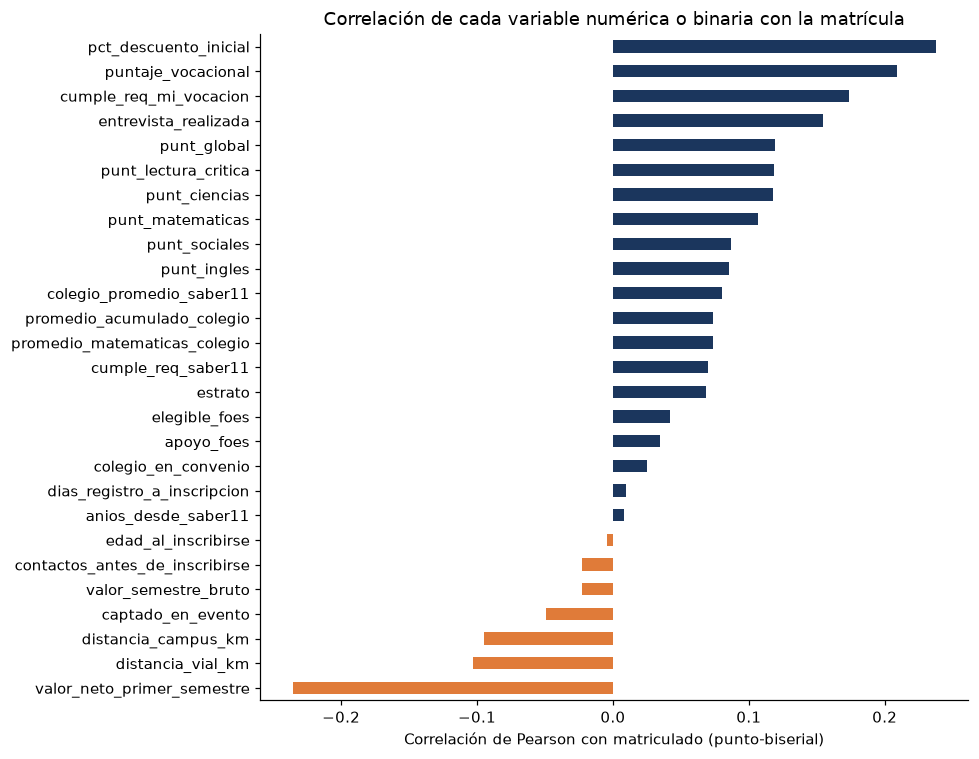

,correlacion_con_matricula
pct_descuento_inicial,0.238
valor_neto_primer_semestre,-0.236
puntaje_vocacional,0.209
cumple_req_mi_vocacion,0.174
entrevista_realizada,0.154
punt_global,0.119
punt_lectura_critica,0.119
punt_ciencias,0.118
punt_matematicas,0.107
distancia_vial_km,-0.103


In [18]:
corr = (t[NUMERICAS + BINARIAS].astype(float).corrwith(t[OBJETIVO]).dropna()
        .sort_values(key=abs, ascending=False))
fig, ax = plt.subplots(figsize=(9, 7))
corr.sort_values().plot(kind="barh", ax=ax, color=[NARANJA if v < 0 else AZUL for v in corr.sort_values()])
ax.set_title("Correlación de cada variable numérica o binaria con la matrícula")
ax.set_xlabel("Correlación de Pearson con matriculado (punto-biserial)")
plt.tight_layout()
plt.show()
corr.round(3).to_frame("correlacion_con_matricula").head(10)

**Lectura**
- **Beca y valor neto:** con beca se matricula entre el 53% y el 59%; sin beca, cerca del 33%. El descuento baja
  el precio del primer semestre.
- **Canal:** inmersión (≈ 61%), referidos, colegio en convenio y Campus Day superan a ExpoEstudiantes, llamadas y
  redes sociales (≈ 32-39%).
- **Distancia (por vías, desde la dirección):** la tasa baja del 53% en el quintil más cercano al 36% en el más lejano.
- **Promedio del colegio:** la tasa de matrícula sube algo con el promedio (de 39% a 50% por quintil), aunque en el
  generador no hay ese efecto: va de la mano con el Saber 11 y la beca (Sprint 4, H-78). Se espera que pese más en el
  objetivo 2: conservar la beca. (El Sprint 4 lo confirmó: los factores académicos son los que más explican la pérdida
  de beca.)
- **Media ICFES del colegio** (`colegio_promedio_saber11`): se describe aquí porque está en la tabla plana, pero desde
  el Sprint 2 **no se usa** en la segmentación ni en los modelos, porque Admisiones no suele tener ese dato (bitácora
  H-43).
- Las correlaciones individuales son **bajas** (la mayor, la del descuento, ronda 0,24), como se espera en un problema
  de comportamiento: ninguna variable sola decide la matrícula. Por eso se necesita un modelo multivariado.

> Recordatorio: el resultado de matrícula es sintético. Estos patrones reflejan los supuestos documentados del
> generador; con los datos reales de Admisiones el mismo cuaderno se vuelve a ejecutar sin cambios.

## 4. Conclusiones del Sprint 1 y próximos pasos
**Lo que se logró**
1. **Conexión segura:** Python lee Supabase con la API. Las credenciales están en `.env` o en los Secretos de Colab, nunca
   en el código. La clave publicable **solo puede leer** el dataset y la base rechaza cualquier escritura.
2. **Dataset plano:** `dataset_matricula` tiene una fila por inscrito, 48 columnas (1 objetivo y 44 predictores), la
   distancia al campus y el promedio del colegio ya calculados, y no tiene datos personales ni variables con fuga.
3. **EDA inicial:** estadística descriptiva, distribuciones, atípicos marcados y nulos clasificados y tratados. Los
   predictores de entrenamiento y de campaña quedan sin vacíos.

**Lo que siguió (sprints 2 a 6, carpeta `sprints/`)**
- **Sprint 2:** 16 columnas nuevas (`probabilidad_acceso_beca`, segmento de rendimiento ICFES, log de la distancia,
  brecha entre el promedio del colegio y el ICFES, promedio estimado, segmento de mercado con k-means…) y un modelo
  base: la tasa histórica de matrícula por beca y canal.
- **Sprint 3:** *pipeline* de scikit-learn con este tratamiento de nulos y modelos de regresión logística, Random
  Forest y XGBoost, con partición temporal por periodo.
- **Sprints 4 a 6:** explicabilidad (SHAP y LIME), prueba con la campaña 2027-1 e impacto en pesos, y el script de
  predicción con el informe ejecutivo.